<a href="https://colab.research.google.com/github/judithwang021/judith-6070/blob/main/Assignments/Case_Study_Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import statsmodels.formula.api as sm
import statsmodels.api as se
import seaborn as sns
import datetime as dt
from sklearn.linear_model import LinearRegression
from scipy import stats
from io import StringIO
import itertools
from pathlib import Path
!pip -q install dataframe_image
import dataframe_image as dfi
import statsmodels.formula.api as smf
from matplotlib.patches import Patch
from google.colab import files

pd.set_eng_float_format(accuracy=3, use_eng_prefix=True)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

from google.colab import userdata
import os

github_token = userdata.get('github_token')
owner = 'judithwang021' # Replace with the GitHub repository owner
repository = 'judith-6070' # Replace with the GitHub repository name

clone_url = f'https://{github_token}@github.com/{owner}/{repository}.git'

# Clone the repository
import subprocess
subprocess.run(['git', 'clone', clone_url])

# Navigate into the cloned repository directory (optional, but often useful)
os.chdir(repository)
print(f"Changed directoGit_HUBry to: {os.getcwd()}")

Changed directoGit_HUBry to: /content/judith-6070


In [4]:
file_path = Path("/content/judith-6070/data/InternetSales.csv")
df = pd.read_csv(file_path, encoding='latin1')
df['OrderDate'] = pd.to_datetime(df['OrderDate'])
df['year'] = df['OrderDate'].dt.year
df.head()

/tmp/ipykernel_2456/3483048246.py:2: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path, encoding='latin1')


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate,year
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.15,3399.99,272.00,85.00,NaN,NaN,2011-01-19,1/31/2011,1/26/2011,2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.62,2319.99,185.60,58.00,NaN,NaN,2013-01-18,1/30/2013,1/25/2013,2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.22,21.98,1.76,0.55,NaN,NaN,2013-01-18,1/30/2013,1/25/2013,2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.94,2384.07,190.73,59.60,NaN,NaN,2013-05-03,5/15/2013,5/10/2013,2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.84,28.99,2.32,0.72,NaN,NaN,2013-05-03,5/15/2013,5/10/2013,2013


In [5]:
df['OrderDate'].agg(['min', 'max'])

,OrderDate
min,2010-12-29
max,2014-01-28


In [6]:
df = df[df['year'].between(2011, 2013)].copy()
df['year'].value_counts().sort_index()

,count
year,
2011,2216
2012,3397
2013,52801


In [7]:
yearly_sales = df.groupby(['year'], as_index=False).agg({'SalesAmount':'sum'})
yearly_sales

,year,SalesAmount
0,2011,7075525.93
1,2012,5842485.20
2,2013,16351550.34


What are the Internet sales of Adventure Works by year for each Country Region?

In [8]:
country_sales = (df.groupby(['year', 'EnglishCountryRegionName'])['SalesAmount']
      .sum()
      .reset_index())
country_sales

,year,EnglishCountryRegionName,SalesAmount
0,2011,Australia,2563732.25
1,2011,Canada,571571.80
2,2011,France,410845.33
3,2011,Germany,520500.16
4,2011,United Kingdom,550591.22
5,2011,United States,2458285.17
6,2012,Australia,2128407.46
7,2012,Canada,307604.52
8,2012,France,648065.54
9,2012,Germany,608657.98


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

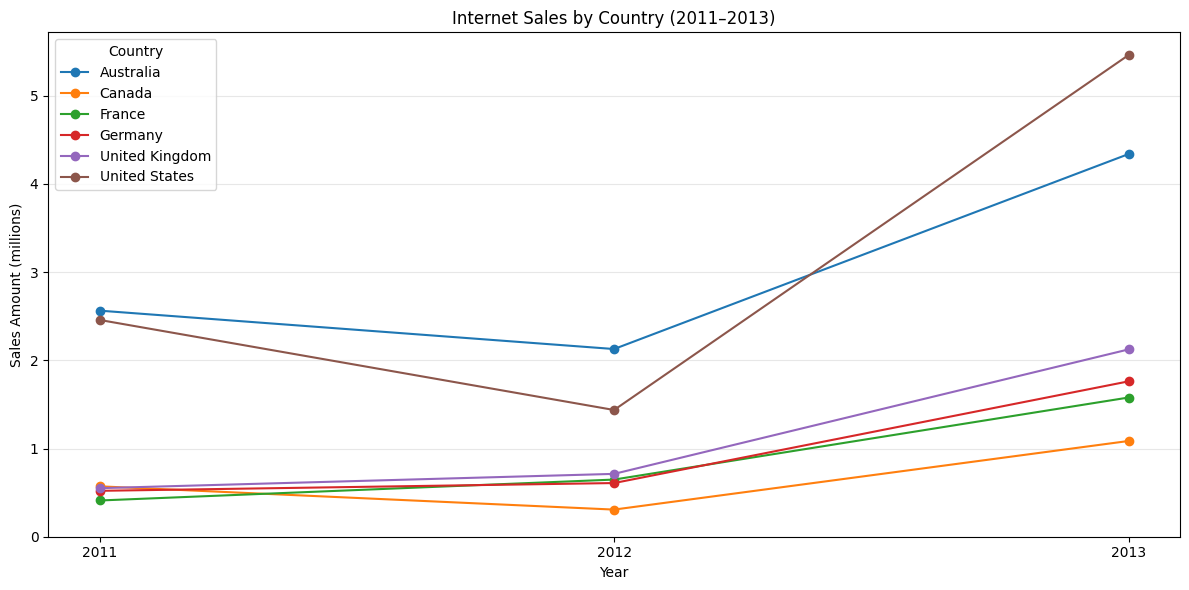

In [9]:
label_offsets = {
    'Australia': (12, 16),
    'United States': (12, -18),
    'Canada': (-30, 30),
    'United Kingdom': (30, 48),
    'Germany': (30, 12),
    'France': (12, -30)}

fig, ax = plt.subplots(figsize=(12, 6))
for country, country_data in country_sales.groupby('EnglishCountryRegionName'):
    ax.plot(
        country_data['year'],
        country_data['SalesAmount'] / 1_000_000,
        marker='o',
        label=country)

ax.set_title('Internet Sales by Country (2011–2013)')
ax.set_xlabel('Year')
ax.set_ylabel('Sales Amount (millions)')
ax.set_xticks([2011, 2012, 2013])
ax.set_ylim(bottom=0)

ax.legend(title='Country')
ax.grid(axis='y', alpha=0.3)

plt.savefig(
    'country_sales.png',
    dpi=300,
    bbox_inches='tight')

files.download('country_sales.png')
plt.tight_layout()
plt.show()

In [10]:
countrysales_table = country_sales.pivot(
    index='EnglishCountryRegionName',
    columns='year',
    values='SalesAmount')

countrysales_table.index.name = 'Country'
countrysales_table.columns.name = 'Year'

countrysales_table.style.format('{:,.2f}')

Year,2011,2012,2013
Country,,,
Australia,"2,563,732.25","2,128,407.46","4,339,443.38"
Canada,"571,571.80","307,604.52","1,085,632.65"
France,"410,845.33","648,065.54","1,578,511.80"
Germany,"520,500.16","608,657.98","1,761,876.36"
United Kingdom,"550,591.22","712,700.96","2,124,007.29"
United States,"2,458,285.17","1,437,048.73","5,462,078.86"


In [11]:
dfi.export(
    countrysales_table.round(2),
    'countrysales_table.png',
    table_conversion='matplotlib')
files.download('countrysales_table.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

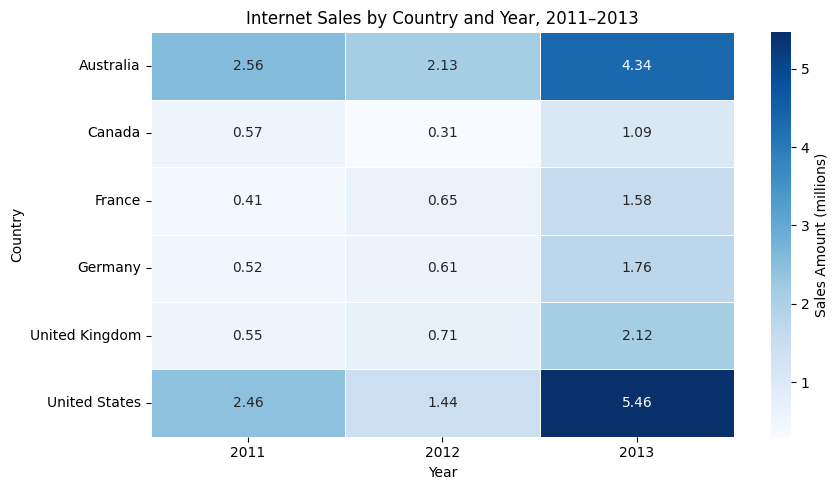

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.heatmap(countrysales_table / 1_000_000,
            annot=True,
            fmt='.2f',
            cmap='Blues',
            linewidths=0.5,
            cbar_kws={'label': 'Sales Amount (millions)'},
            ax=ax)

ax.set_title('Internet Sales by Country and Year, 2011–2013')
ax.set_xlabel('Year')
ax.set_ylabel('Country')
ax.tick_params(axis='y', labelrotation=0)

plt.tight_layout()
plt.show()

Generate summary statistics including min, max, and standard deviation for Yearly Income, Gender by Country Regions.  

In [13]:
customer_columns = ['EnglishCountryRegionName', 'Gender', 'YearlyIncome']

consistency_check = (
    df.groupby('CustomerKey')[customer_columns]
      .nunique(dropna=False))

inconsistent_customers = consistency_check[(consistency_check > 1).any(axis=1)]
print('Number of customers with inconsistent information:', len(inconsistent_customers))

Number of customers with inconsistent information: 0


In [14]:
customers = (df[['CustomerKey'] + customer_columns]
    .drop_duplicates(subset='CustomerKey')
    .copy())

print('Number of sales records:', len(df))
print('Number of customers:', len(customers))

customers.head()

Number of sales records: 58414
Number of customers: 17977


,CustomerKey,EnglishCountryRegionName,Gender,YearlyIncome
0,11000,Australia,M,90000
8,11001,Australia,M,60000
19,11002,Australia,M,60000
23,11003,Australia,F,70000
32,11004,Australia,F,80000


In [15]:
income_summary = (
    customers.groupby(['EnglishCountryRegionName', 'Gender'])
    .agg(
        Customer_Count=('CustomerKey', 'size'),
        Mean_Income=('YearlyIncome', 'mean'),
        Median_Income=('YearlyIncome', 'median'),
        Min_Income=('YearlyIncome', 'min'),
        Max_Income=('YearlyIncome', 'max'),
        Std_Income=('YearlyIncome', 'std'))
.reset_index())

income_summary.columns = ['Country', 'Gender', 'Customer Count',
                          'Mean Income', 'Median Income',
                          'Min Income', 'Max Income', 'Income Std. Dev.']

income_summary.style.format({'Customer Count': '{:,}',
                             'Mean Income': '{:,.2f}',
                             'Median Income': '{:,.2f}',
                             'Min Income': '{:,.2f}',
                             'Max Income': '{:,.2f}',
                             'Income Std. Dev.': '{:,.2f}'})

,Country,Gender,Customer Count,Mean Income,Median Income,Min Income,Max Income,Income Std. Dev.
0,Australia,F,"1,753","65,328.01","70,000.00","10,000.00","160,000.00","31,038.31"
1,Australia,M,"1,790","63,346.37","70,000.00","10,000.00","170,000.00","32,346.77"
2,Canada,F,755,"56,635.76","60,000.00","10,000.00","170,000.00","19,231.07"
3,Canada,M,790,"57,860.76","60,000.00","10,000.00","170,000.00","21,297.72"
4,France,F,858,"35,221.45","30,000.00","10,000.00","110,000.00","26,753.73"
5,France,M,888,"35,822.07","30,000.00","10,000.00","110,000.00","27,356.26"
6,Germany,F,845,"43,585.80","30,000.00","10,000.00","130,000.00","35,563.09"
7,Germany,M,875,"41,794.29","30,000.00","10,000.00","130,000.00","35,052.80"
8,United Kingdom,F,910,"52,505.49","30,000.00","10,000.00","170,000.00","48,405.69"
9,United Kingdom,M,964,"52,313.28","30,000.00","10,000.00","170,000.00","48,704.31"


In [16]:
dfi.export(
    income_summary.round(2),
    'income_summary.png',
    table_conversion='matplotlib')
files.download('income_summary.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

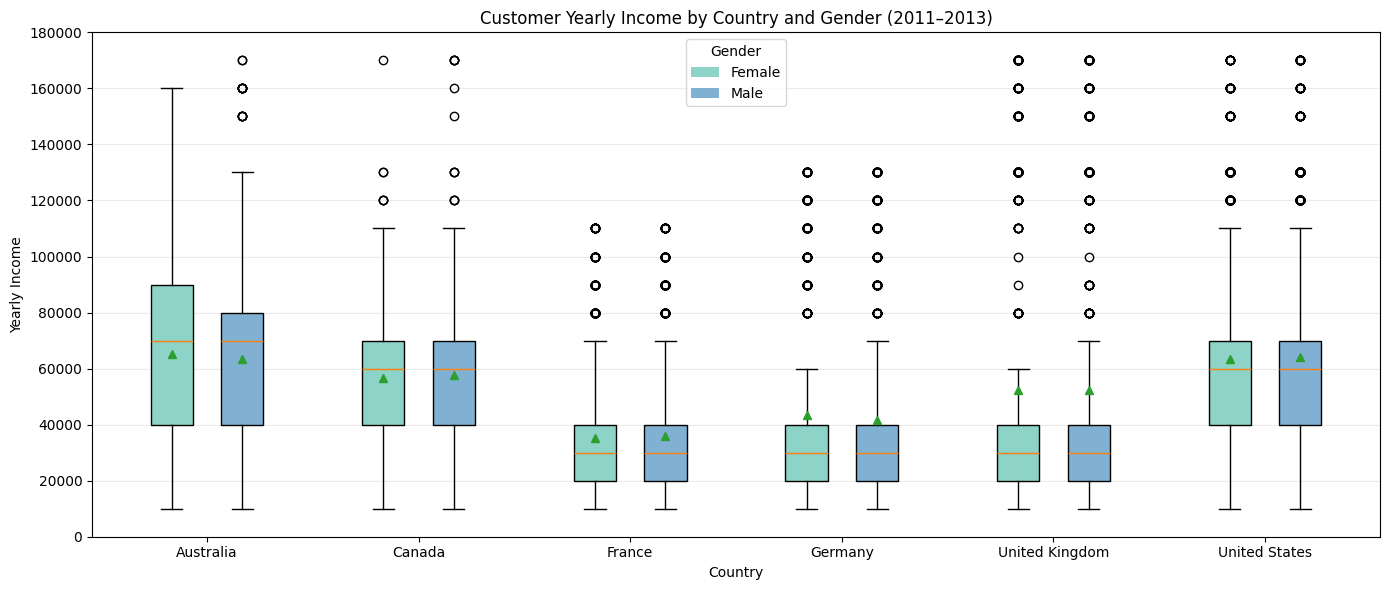

In [17]:
from seaborn.categorical import boxplot
countries = sorted(customers['EnglishCountryRegionName'].unique())
colors = ['#8DD3C7', '#80B1D3']
plt.figure(figsize=(14, 6))

for i, country in enumerate(countries):
    country_data = customers[
        customers['EnglishCountryRegionName'] == country]

    boxes = plt.boxplot(
        [country_data.loc[country_data['Gender'] == 'F', 'YearlyIncome'].dropna(),
         country_data.loc[country_data['Gender'] == 'M', 'YearlyIncome'].dropna()],
        positions=[i * 3, i * 3 + 1],
        widths=0.6,
        showmeans=True,
        patch_artist=True,
        manage_ticks=False)
    for box, color in zip(boxes['boxes'], colors):
        box.set_facecolor(color)

plt.xticks(
    [i * 3 + 0.5 for i in range(len(countries))],
    countries)

plt.legend(
    handles=[
        Patch(facecolor=colors[0], label='Female'),
        Patch(facecolor=colors[1], label='Male')],
    title='Gender',
    loc='upper center')

plt.xlabel('Country')
plt.ylabel('Yearly Income')
plt.title('Customer Yearly Income by Country and Gender (2011–2013)')
plt.ylim(0, 180000)
plt.grid(axis='y', alpha=0.25)

plt.savefig(
    'yearly_income.png',
    dpi=300,
    bbox_inches='tight')

files.download('yearly_income.png')
plt.tight_layout()
plt.show()

What is the average price of the product category that generates the most sales?

In [18]:
product_names = sorted(df['EnglishProductName'].dropna().unique())
print('Number of product names:', len(product_names))

Number of product names: 130


In [19]:
for name in product_names:
    print(name)

AWC Logo Cap
All-Purpose Bike Stand
Bike Wash - Dissolver
Classic Vest, L
Classic Vest, M
Classic Vest, S
Fender Set - Mountain
HL Mountain Tire
HL Road Tire
Half-Finger Gloves, L
Half-Finger Gloves, M
Half-Finger Gloves, S
Hitch Rack - 4-Bike
Hydration Pack - 70 oz.
LL Mountain Tire
LL Road Tire
Long-Sleeve Logo Jersey, L
Long-Sleeve Logo Jersey, M
Long-Sleeve Logo Jersey, S
Long-Sleeve Logo Jersey, XL
ML Mountain Tire
ML Road Tire
Mountain Bottle Cage
Mountain Tire Tube
Mountain-100 Black, 38
Mountain-100 Black, 42
Mountain-100 Black, 44
Mountain-100 Black, 48
Mountain-100 Silver, 38
Mountain-100 Silver, 42
Mountain-100 Silver, 44
Mountain-100 Silver, 48
Mountain-200 Black, 38
Mountain-200 Black, 42
Mountain-200 Black, 46
Mountain-200 Silver, 38
Mountain-200 Silver, 42
Mountain-200 Silver, 46
Mountain-400-W Silver, 38
Mountain-400-W Silver, 40
Mountain-400-W Silver, 42
Mountain-400-W Silver, 46
Mountain-500 Black, 40
Mountain-500 Black, 42
Mountain-500 Black, 44
Mountain-500 Black, 4

In [47]:
productsales = (
    df.groupby('EnglishProductName')
    .agg(
        Total_Sales=('SalesAmount', 'sum'),
        Units_Sold=('OrderQuantity', 'sum')))

productsales['Average_Selling_Price'] = (
    productsales['Total_Sales'] / productsales['Units_Sold'])

display(
    productsales.sort_values('Total_Sales', ascending=False)
    .head(10)
    .style.format({
        'Total_Sales': '{:,.2f}',
        'Units_Sold': '{:,.0f}'}))

,Total_Sales,Units_Sold,Average_Selling_Price
EnglishProductName,,,
"Mountain-200 Black, 46","1,373,469.55",620,2215.273465
"Mountain-200 Black, 42","1,363,142.09",614,2220.101129
"Mountain-200 Silver, 38","1,339,462.79",596,2247.420789
"Mountain-200 Silver, 46","1,301,100.10",580,2243.276032
"Mountain-200 Black, 38","1,294,866.14",582,2224.855913
"Mountain-200 Silver, 42","1,257,434.57",560,2245.418880
"Road-150 Red, 48","1,198,720.45",335,3578.270000
"Road-150 Red, 62","1,195,142.18",334,3578.270000
"Road-150 Red, 52","1,077,059.27",301,3578.270000


In [49]:
productsales['Average_Selling_Price'] = (
    productsales['Total_Sales'] / productsales['Units_Sold'])
display(
    productsales.sort_values('Units_Sold', ascending=False)
    .head(10)
    .style.format({
        'Total_Sales': '{:,.2f}',
        'Units_Sold': '{:,.0f}'}))

,Total_Sales,Units_Sold,Average_Selling_Price
EnglishProductName,,,
Water Bottle - 30 oz.,"20,449.02","4,098",4.990000
Patch Kit/8 Patches,"6,938.70","3,030",2.290000
Mountain Tire Tube,"14,615.71","2,929",4.990000
Road Tire Tube,"8,897.70","2,230",3.990000
"Sport-100 Helmet, Red","75,473.43","2,157",34.990000
AWC Logo Cap,"18,941.93","2,107",8.990000
"Sport-100 Helmet, Blue","71,379.60","2,040",34.990000
Fender Set - Mountain,"44,553.46","2,027",21.980000
"Sport-100 Helmet, Black","70,084.97","2,003",34.990000


In [21]:
def product(name):
    if name.startswith(('Mountain-', 'Road-', 'Touring-')):
        return 'Bikes'
    elif any(word in name for word in
             ['Cap', 'Vest', 'Gloves', 'Jersey', 'Socks', 'Shorts']):
        return 'Clothing'
    else:
        return 'Accessories'

df['ProductCategory'] = df['EnglishProductName'].apply(product)

In [22]:
category_summary = (
    df.groupby('ProductCategory')
      .agg(
          Total_Sales=('SalesAmount', 'sum'),
          Units_Sold=('OrderQuantity', 'sum')
      )
      .sort_values('Total_Sales', ascending=False))

# Calculate the average realized selling price per unit
category_summary['Average_Selling_Price'] = (
    category_summary['Total_Sales'] / category_summary['Units_Sold'])

category_summary.style.format({
    'Total_Sales': '{:,.2f}',
    'Units_Sold': '{:,.0f}',
    'Average_Selling_Price': '{:,.2f}'})

,Total_Sales,Units_Sold,Average_Selling_Price
ProductCategory,,,
Bikes,"28,274,723.61","15,191","1,861.28"
Accessories,"670,388.61","34,515",19.42
Clothing,"324,449.24","8,708",37.26


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

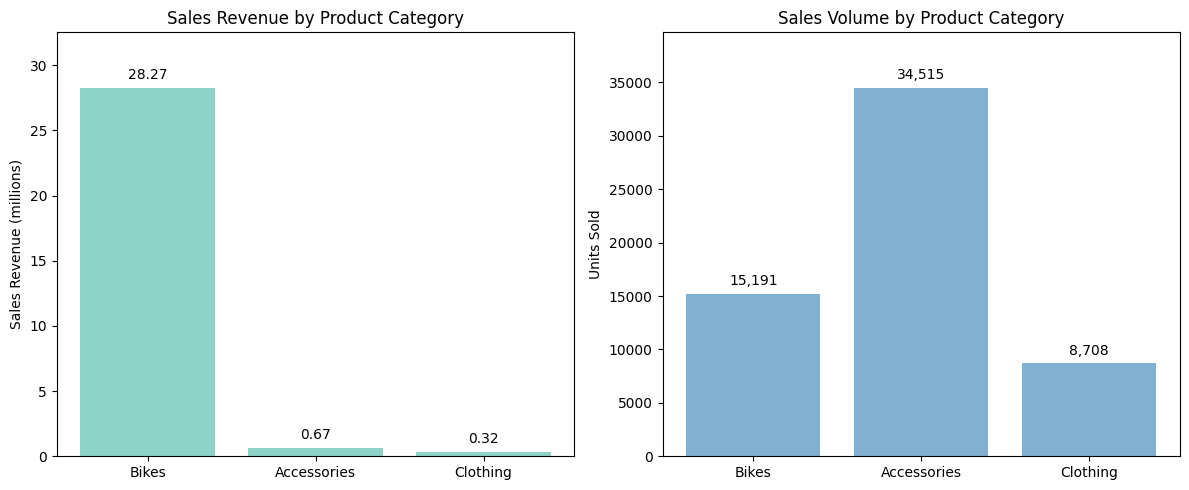

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

revenue_bars = axes[0].bar(
    category_summary.index,
    category_summary['Total_Sales'] / 1_000_000,
    color='#8DD3C7')

axes[0].bar_label(revenue_bars, fmt='%.2f', padding=4)
axes[0].set_title('Sales Revenue by Product Category')
axes[0].set_ylabel('Sales Revenue (millions)')
axes[0].margins(y=0.15)

volume_bars = axes[1].bar(
    category_summary.index,
    category_summary['Units_Sold'],
    color='#80B1D3')

axes[1].bar_label(
    volume_bars,
    labels=[f'{value:,.0f}' for value in category_summary['Units_Sold']],
    padding=4)
axes[1].set_title('Sales Volume by Product Category')
axes[1].set_ylabel('Units Sold')
axes[1].margins(y=0.15)

plt.savefig(
    'product_category.png',
    dpi=300,
    bbox_inches='tight')

files.download('product_category.png')

plt.tight_layout()
plt.show()

In [24]:
def sales_group(name):
    if name.startswith('Mountain-'):
        return 'Mountain Bikes'
    elif name.startswith('Road-'):
        return 'Road Bikes'
    elif name.startswith('Touring-'):
        return 'Touring Bikes'
    else:
        return product(name)

df['SalesGroup'] = df['EnglishProductName'].apply(sales_group)

In [25]:
bike_sales = df[df['ProductCategory'] == 'Bikes']

bike_summary = (
    bike_sales.groupby('SalesGroup')
    .agg(
        Total_Sales=('SalesAmount', 'sum'),
        Units_Sold=('OrderQuantity', 'sum')
    )
    .sort_values('Total_Sales', ascending=False))

bike_summary['Average_Selling_Price'] = (
    bike_summary['Total_Sales'] / bike_summary['Units_Sold'])

bike_summary.style.format({
    'Total_Sales': '{:,.2f}',
    'Units_Sold': '{:,.0f}',
    'Average_Selling_Price': '{:,.2f}'})

,Total_Sales,Units_Sold,Average_Selling_Price
SalesGroup,,,
Road Bikes,"14,494,137.95","8,059","1,798.50"
Mountain Bikes,"9,935,784.61","4,965","2,001.17"
Touring Bikes,"3,844,801.05","2,167","1,774.25"


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

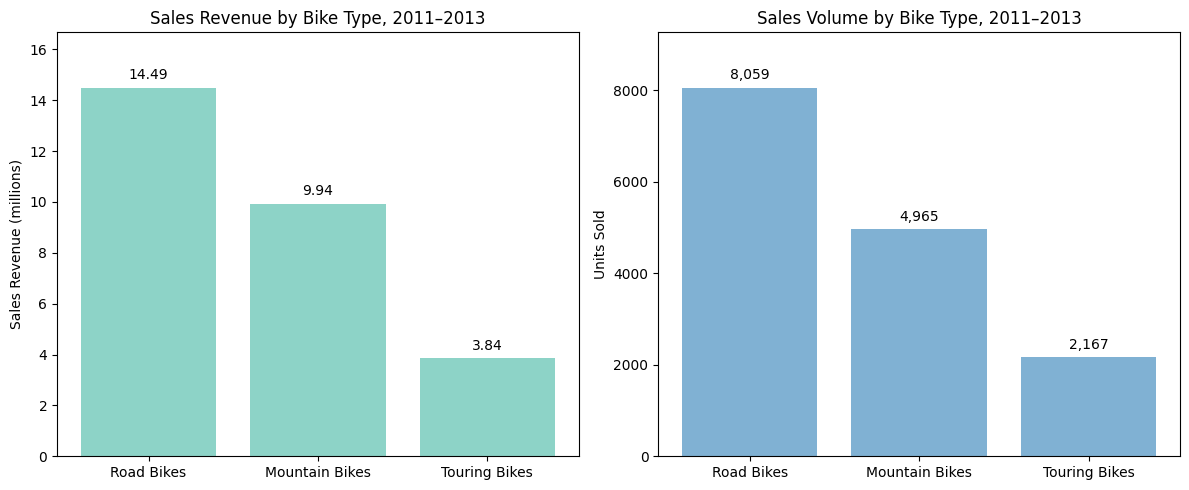

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

revenue_bars = axes[0].bar(
    bike_summary.index,
    bike_summary['Total_Sales'] / 1_000_000,
    color='#8DD3C7')

axes[0].bar_label(revenue_bars, fmt='%.2f', padding=4)
axes[0].set_title('Sales Revenue by Bike Type, 2011–2013')
axes[0].set_ylabel('Sales Revenue (millions)')
axes[0].margins(y=0.15)

volume_bars = axes[1].bar(
    bike_summary.index,
    bike_summary['Units_Sold'],
    color='#80B1D3')

axes[1].bar_label(
    volume_bars,
    labels=[f'{value:,.0f}' for value in bike_summary['Units_Sold']],
    padding=4)
axes[1].set_title('Sales Volume by Bike Type, 2011–2013')
axes[1].set_ylabel('Units Sold')
axes[1].margins(y=0.15)

plt.savefig(
    'bike.png',
    dpi=300,
    bbox_inches='tight')

files.download('bike.png')

plt.tight_layout()
plt.show()

In [27]:
ysales_category = df.pivot_table(
    index='year',
    columns='ProductCategory',
    values='SalesAmount',
    aggfunc='sum',
    fill_value=0)

ysales_category.style.format('{:,.2f}')

ProductCategory,Accessories,Bikes,Clothing
year,,,
2011,0.00,"7,075,525.93",0.00
2012,"2,147.08","5,839,695.33",642.79
2013,"668,241.53","15,359,502.36","323,806.45"


In [28]:
category_coverage = (
    df.groupby('ProductCategory')
    .agg(
        First_Sale=('OrderDate', 'min'),
        Last_Sale=('OrderDate', 'max'),
        Sales_Records=('OrderDate', 'size')))

category_coverage

,First_Sale,Last_Sale,Sales_Records
ProductCategory,,,
Accessories,2012-12-28,2013-12-31,34515
Bikes,2011-01-01,2013-12-28,15191
Clothing,2012-12-28,2013-12-31,8708


In [29]:
category_summary_2013 = (
    df[df['year'] == 2013]
    .groupby('ProductCategory')
    .agg(
        Total_Sales=('SalesAmount', 'sum'),
        Units_Sold=('OrderQuantity', 'sum'))
    .sort_values('Total_Sales', ascending=False))

category_summary_2013['Average_Selling_Price'] = (
    category_summary_2013['Total_Sales']
    / category_summary_2013['Units_Sold'])

category_summary_2013.style.format({
    'Total_Sales': '{:,.2f}',
    'Units_Sold': '{:,.0f}',
    'Average_Selling_Price': '{:,.2f}'})

,Total_Sales,Units_Sold,Average_Selling_Price
ProductCategory,,,
Bikes,"15,359,502.36","9,706","1,582.48"
Accessories,"668,241.53","34,409",19.42
Clothing,"323,806.45","8,686",37.28


Does owning a home make a difference in sales? Explain your analysis.

In [30]:
home_check = df.groupby('CustomerKey')['HouseOwnerFlag'].nunique(dropna=False)

print('Number of customers with inconsistent homeownership status:',
    (home_check > 1).sum())

print('Homeownership values:', df['HouseOwnerFlag'].unique())
print('Missing homeownership records:', df['HouseOwnerFlag'].isna().sum())

Number of customers with inconsistent homeownership status: 0
Homeownership values: [1 0]
Missing homeownership records: 0


In [31]:
customer_sales = (
    df.groupby('CustomerKey')
    .agg(
        HouseOwnerFlag=('HouseOwnerFlag', 'first'),
        Total_Spending=('SalesAmount', 'sum'),
        Order_Count=('SalesOrderNumber', 'nunique'))
    .reset_index())

customer_sales['Homeownership'] = customer_sales['HouseOwnerFlag'].map({
    0: 'Non-homeowner',
    1: 'Homeowner'})

In [32]:
home_summary = (
    customer_sales.groupby('Homeownership')
    .agg(
        Customer_Count=('CustomerKey', 'size'),
        Total_Sales=('Total_Spending', 'sum'),
        Mean_Customer_Spending=('Total_Spending', 'mean'),
        Median_Customer_Spending=('Total_Spending', 'median'),
        Total_Orders=('Order_Count', 'sum'),
        Mean_Orders_Per_Customer=('Order_Count', 'mean')))

home_summary['Average_Order_Value'] = (
    home_summary['Total_Sales'] / home_summary['Total_Orders'])

home_summary.style.format({
    'Customer_Count': '{:,.0f}',
    'Total_Sales': '{:,.2f}',
    'Mean_Customer_Spending': '{:,.2f}',
    'Median_Customer_Spending': '{:,.2f}',
    'Total_Orders': '{:,.0f}',
    'Mean_Orders_Per_Customer': '{:.2f}',
    'Average_Order_Value': '{:,.2f}'})

,Customer_Count,Total_Sales,Mean_Customer_Spending,Median_Customer_Spending,Total_Orders,Mean_Orders_Per_Customer,Average_Order_Value
Homeownership,,,,,,,
Homeowner,"12,155","20,327,954.85","1,672.39",553.97,"18,445",1.52,"1,102.08"
Non-homeowner,"5,822","8,941,606.61","1,535.83",539.99,"8,329",1.43,"1,073.55"


In [33]:
dfi.export(
    home_summary.round(2),
    'home_summary.png',
    table_conversion='matplotlib')
files.download('home_summary.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:
customer_info = (
    df[['CustomerKey', 'HouseOwnerFlag',
        'YearlyIncome', 'EnglishCountryRegionName']]
    .drop_duplicates(subset='CustomerKey'))

regression_data = customer_sales[
    ['CustomerKey', 'Total_Spending']].merge(
    customer_info,
    on='CustomerKey',
    how='left',
    validate='one_to_one')

regression_data.head()

,CustomerKey,Total_Spending,HouseOwnerFlag,YearlyIncome,EnglishCountryRegionName
0,11000,8248.99,1,90000,Australia
1,11001,6383.88,0,60000,Australia
2,11002,8114.04,1,60000,Australia
3,11003,4739.30,0,70000,Australia
4,11004,8196.01,1,80000,Australia


In [35]:
lm1 = smf.ols('Total_Spending ~ HouseOwnerFlag + YearlyIncome + C(EnglishCountryRegionName)',
    data=regression_data).fit(cov_type='HC3')

print(lm1.summary())

                            OLS Regression Results                            
Dep. Variable:         Total_Spending   R-squared:                       0.083
Model:                            OLS   Adj. R-squared:                  0.083
Method:                 Least Squares   F-statistic:                     170.5
Date:                Sun, 01 Nov 2026   Prob (F-statistic):          2.41e-245
Time:                        04:06:09   Log-Likelihood:            -1.6255e+05
No. Observations:               17977   AIC:                         3.251e+05
Df Residuals:                   17969   BIC:                         3.252e+05
Df Model:                           7                                         
Covariance Type:                  HC3                                         
                                                    coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------

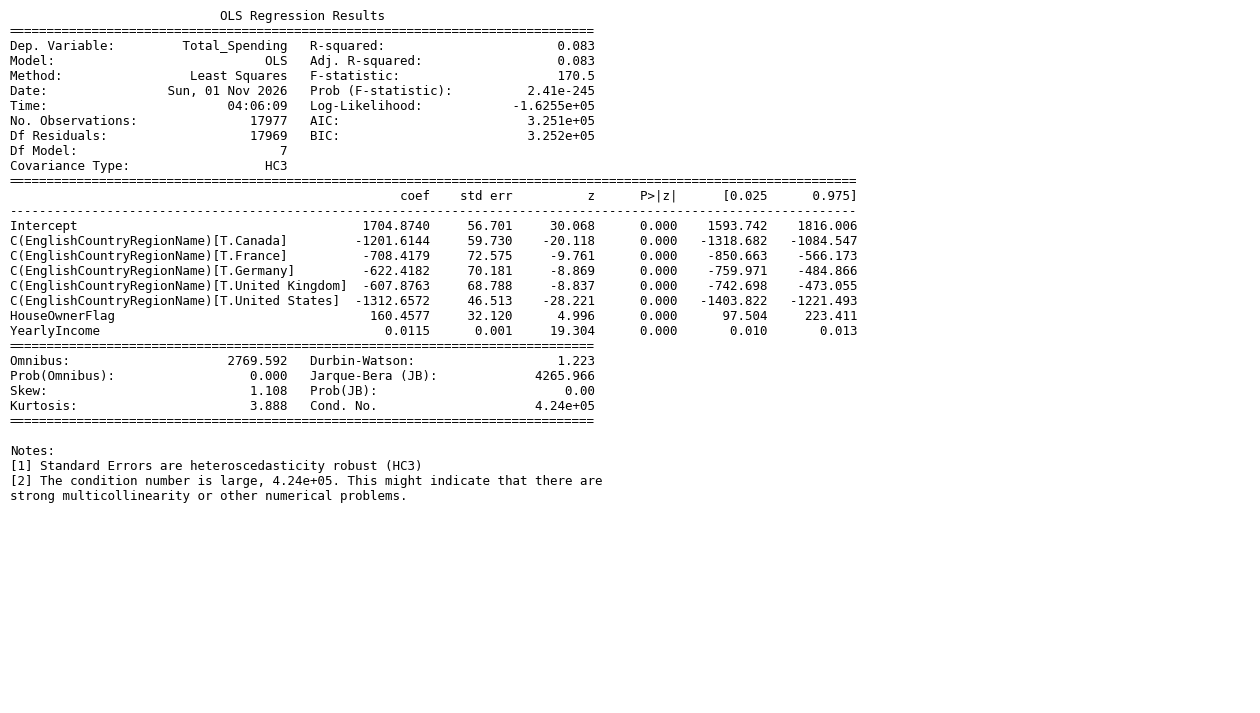

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:
reg_fig, reg_ax = plt.subplots(figsize=(16, 9))
reg_ax.axis('off')

reg_ax.text(
    0, 1,
    lm1.summary().as_text(),
    fontfamily='monospace',
    fontsize=9,
    va='top',
    transform=reg_ax.transAxes)

reg_fig.savefig(
    'ols_regression_results.png',
    dpi=300,
    bbox_inches='tight')

plt.show()

files.download('ols_regression_results.png')

In [37]:
lm2 = smf.ols(
    'Total_Spending ~ HouseOwnerFlag + YearlyIncome',
    data=regression_data).fit(cov_type='HC3')

print('Homeownership coefficient without country controls:',
    round(lm2.params['HouseOwnerFlag'], 2))

print('Homeownership coefficient with country controls:',
    round(lm1.params['HouseOwnerFlag'], 2))

Homeownership coefficient without country controls: 102.23
Homeownership coefficient with country controls: 160.46


Recommendation

In [38]:
from sklearn.ensemble import RandomForestRegressor
from sklearn  import linear_model
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from math import sqrt
from sklearn.model_selection import train_test_split

In [39]:
monthly_sales = (
    df.set_index('OrderDate')['SalesAmount']
      .resample('MS')
      .sum(min_count=1))

forecast_data = monthly_sales.reset_index()
forecast_data.columns = ['Date', 'Sales']

forecast_data['Time'] = range(len(forecast_data))
forecast_data['Month'] = forecast_data['Date'].dt.month

train_data = forecast_data[forecast_data['Date'].dt.year < 2013]
test_data = forecast_data[forecast_data['Date'].dt.year == 2013]

In [40]:
forest = RandomForestRegressor(
    n_estimators=100,
    max_depth=3,
    random_state=42)

forest.fit(
    train_data[['Time', 'Month']],
    train_data['Sales'])

forest_prediction = forest.predict(
    test_data[['Time', 'Month']])

mae = mean_absolute_error(test_data['Sales'], forest_prediction)
print(f'Random Forest MAE: {mae:,.2f}')

Random Forest MAE: 862,280.80


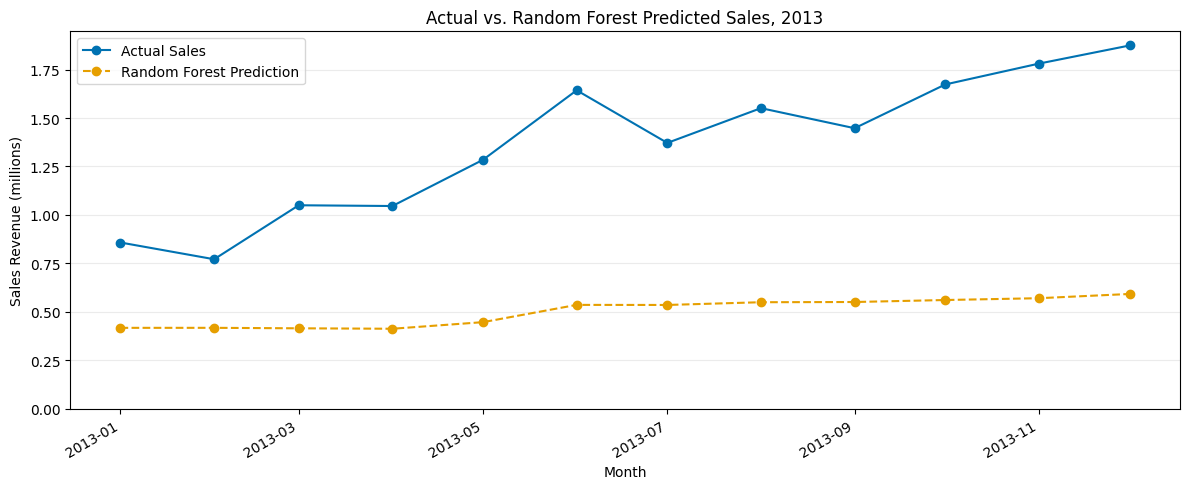

In [41]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    test_data['Date'],
    test_data['Sales'] / 1_000_000,
    marker='o',
    color='#0072B2',
    label='Actual Sales')

ax.plot(
    test_data['Date'],
    forest_prediction / 1_000_000,
    marker='o',
    linestyle='--',
    color='#E69F00',
    label='Random Forest Prediction')

ax.set_title('Actual vs. Random Forest Predicted Sales, 2013')
ax.set_xlabel('Month')
ax.set_ylabel('Sales Revenue (millions)')
ax.set_ylim(bottom=0)
ax.legend()
ax.grid(axis='y', alpha=0.25)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

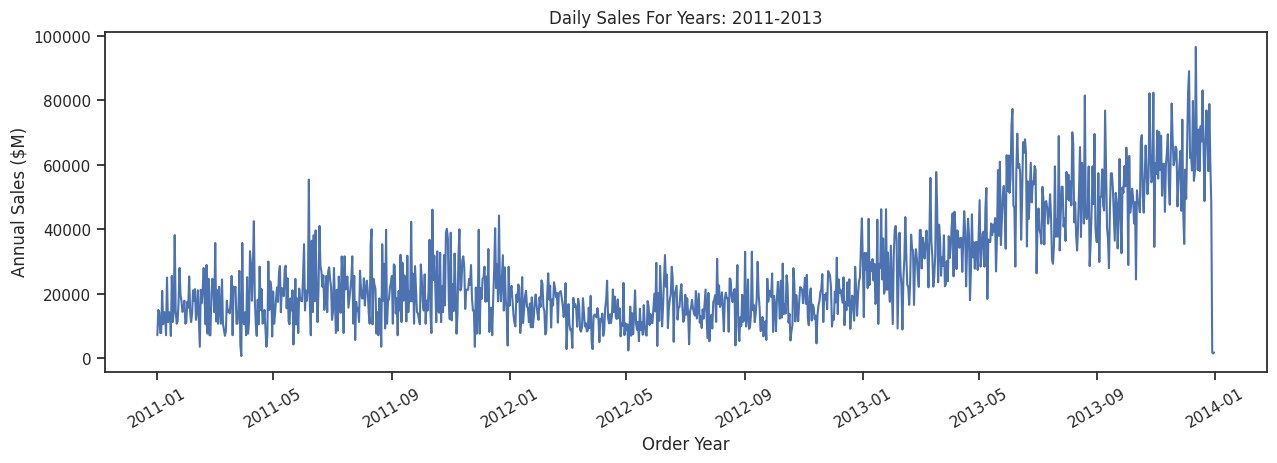

In [42]:
yearly_sales = df.groupby(['OrderDate'], as_index=True).agg({'SalesAmount':'sum'})
yearly_sales
sns.set(rc={"figure.figsize":(15, 5)}) #width=15, height=5
sns.set_theme(style="ticks")

fig, ax1 = plt.subplots(figsize=(15, 5))
fig.autofmt_xdate(ha='center')
_ = ax1.set(
    title="Daily Sales For Years: 2011-2013",
    #xticklabels=["2010", "2011", "2012", "2013", "2014"],
    xlabel="Order Year",
    ylabel='Annual Sales ($M)'
)
plt.plot(yearly_sales.index,yearly_sales['SalesAmount'])

Random Forest RMSE: 124,409.28


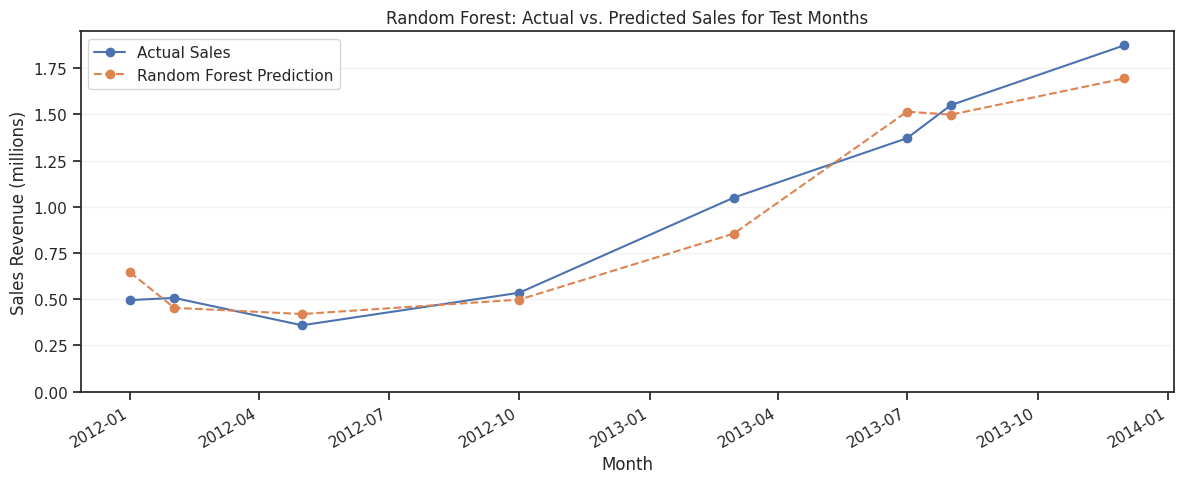

In [43]:
monthly_data = (
    df.set_index('OrderDate')['SalesAmount']
      .resample('MS')
      .sum(min_count=1)
      .reset_index())

monthly_data['MonthNumber'] = range(len(monthly_data))

X = monthly_data[['MonthNumber']]
y = monthly_data['SalesAmount']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42)

# Train the random forest
forest_month = RandomForestRegressor(random_state=42)
forest_month.fit(X_train, y_train)

# Predict the test months
y_hat = forest_month.predict(X_test)

forest_rmse = mean_squared_error(y_test, y_hat) ** 0.5
print(f'Random Forest RMSE: {forest_rmse:,.2f}')

comparison = pd.DataFrame({
    'Date': monthly_data.loc[X_test.index, 'OrderDate'],
    'Actual': y_test.to_numpy(),
    'Predicted': y_hat
}).sort_values('Date')

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    comparison['Date'],
    comparison['Actual'] / 1_000_000,
    marker='o',
    label='Actual Sales'
)

ax.plot(
    comparison['Date'],
    comparison['Predicted'] / 1_000_000,
    marker='o',
    linestyle='--',
    label='Random Forest Prediction'
)

ax.set_title('Random Forest: Actual vs. Predicted Sales for Test Months')
ax.set_xlabel('Month')
ax.set_ylabel('Sales Revenue (millions)')
ax.set_ylim(bottom=0)
ax.legend()
ax.grid(axis='y', alpha=0.25)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

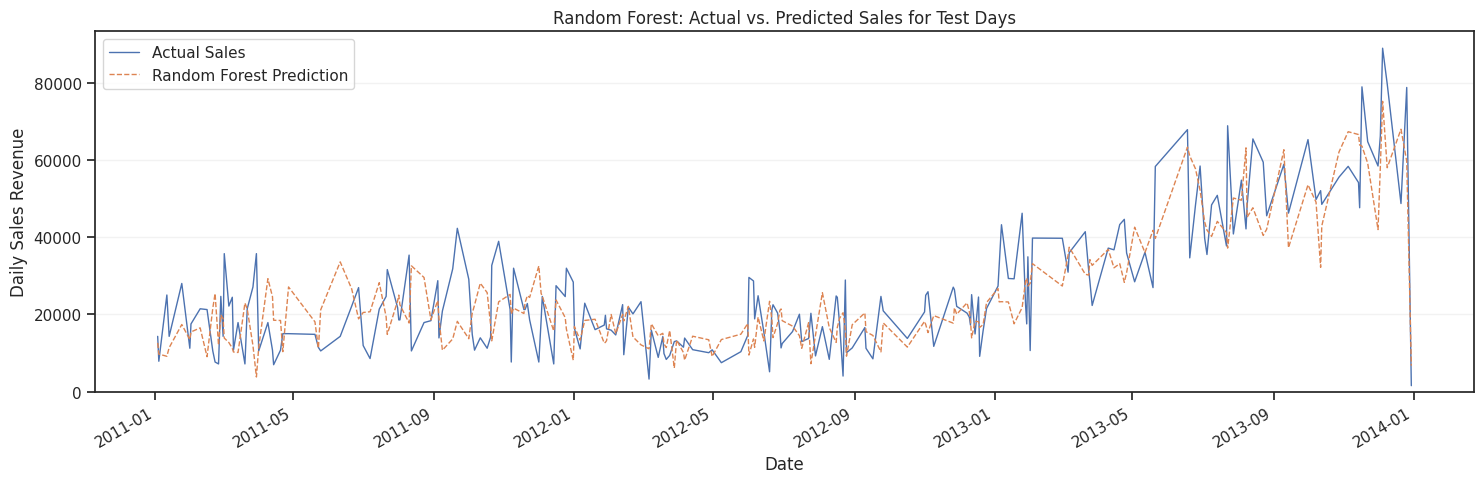

In [44]:
daily_data = (
    df.set_index('OrderDate')['SalesAmount']
      .resample('D')
      .sum(min_count=1)
      .reset_index())

daily_data = daily_data.dropna(subset=['SalesAmount']).reset_index(drop=True)
daily_data['DayNumber'] = (
    daily_data['OrderDate'] - daily_data['OrderDate'].min()
).dt.days

X = daily_data[['DayNumber']]
y = daily_data['SalesAmount']

X_train_daily, X_test_daily, y_train_daily, y_test_daily = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42)


forest_daily = RandomForestRegressor(random_state=42)
forest_daily.fit(X_train_daily, y_train_daily)

daily_prediction = forest_daily.predict(X_test_daily)

daily_rmse = mean_squared_error(y_test_daily, daily_prediction) ** 0.5
daily_mae = mean_absolute_error(y_test_daily, daily_prediction)

daily_comparison = pd.DataFrame({
    'Date': daily_data.loc[X_test_daily.index, 'OrderDate'],
    'Actual': y_test_daily.to_numpy(),
    'Predicted': daily_prediction
}).sort_values('Date')

fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(
    daily_comparison['Date'],
    daily_comparison['Actual'],
    label='Actual Sales',
    linewidth=1)

ax.plot(
    daily_comparison['Date'],
    daily_comparison['Predicted'],
    label='Random Forest Prediction',
    linestyle='--',
    linewidth=1)

ax.set_title('Random Forest: Actual vs. Predicted Sales for Test Days')
ax.set_xlabel('Date')
ax.set_ylabel('Daily Sales Revenue')
ax.set_ylim(bottom=0)
ax.legend()
ax.grid(axis='y', alpha=0.25)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()